In [ ]:
from pathlib import Path
import pandas as pd

caminho_renda = Path("../dados/brutos/renda/Agregados_por_setores_renda_responsavel_BR.csv")

# Le só uma amostra para conferir o formato antes de carregar o CSV inteiro.
amostra_renda = pd.read_csv(
    caminho_renda,
    sep=";",
    dtype="string",
    nrows=5,
    encoding="utf-8-sig",
)

print("Colunas:", amostra_renda.columns.tolist())
print(amostra_renda.to_string(index=False))

Colunas: ['CD_SETOR', 'V06001', 'V06002', 'V06003', 'V06004', 'V06005', 'V06006']
       CD_SETOR V06001 V06002 V06003  V06004      V06005 V06006
110001505000002    336    928   1.67 2453.03 13047638.93   1212
110001505000003    208    556   1.79 2126.44  2348222.39   1500
110001505000004     85    222    1.6 1664.94  1270082.06   1200
110001505000006    281    783   2.41  1722.4   1446560.6   1200
110001505000007    291    748   1.38 1930.94  2255368.87   1212


In [2]:
partes_salvador = []

for lote in pd.read_csv(
    caminho_renda,
    sep=";",
    encoding="utf-8-sig",
    usecols=["CD_SETOR", "V06001", "V06004"],
    dtype="string",
    chunksize=100_000,
):
    lote["CD_SETOR"] = lote["CD_SETOR"].str.strip()
    em_salvador = lote["CD_SETOR"].str.startswith("2927408", na=False)
    partes_salvador.append(lote.loc[em_salvador].copy())

renda_salvador = pd.concat(partes_salvador, ignore_index=True)

print("Linhas de Salvador:", len(renda_salvador))
print("Códigos únicos:", renda_salvador["CD_SETOR"].nunique())
print("Códigos duplicados:", renda_salvador["CD_SETOR"].duplicated().sum())

for coluna in ["V06001", "V06004"]:
    original = renda_salvador[coluna].str.strip()
    numerica = pd.to_numeric(original, errors="coerce")
    renda_salvador[f"{coluna}_num"] = numerica

    print(f"\n{coluna}")
    print("Ausentes ou não numéricos:", numerica.isna().sum())
    print("Valores iguais a zero:", numerica.eq(0).sum())
    print("Marcadores encontrados:")
    print(original[numerica.isna()].value_counts(dropna=False).to_string())

Linhas de Salvador: 4504
Códigos únicos: 4504
Códigos duplicados: 0

V06001
Ausentes ou não numéricos: 28
Valores iguais a zero: 0
Marcadores encontrados:
V06001
X    28

V06004
Ausentes ou não numéricos: 28
Valores iguais a zero: 0
Marcadores encontrados:
V06004
X    28


In [3]:
import geopandas as gpd

setores_base = gpd.read_file(
    "../dados/brutos/populacao/BA_setores_CD2022.gpkg",
    columns=["CD_SETOR", "v0001"],
    ignore_geometry=True,
)

setores_base["CD_SETOR"] = setores_base["CD_SETOR"].astype("string").str.strip()
setores_base = (
    setores_base.loc[setores_base["CD_SETOR"].str.startswith("2927408", na=False)]
    .drop_duplicates("CD_SETOR")  # No notebook 04, você verificou que v0001 era igual nas repetições.
)

auditoria = setores_base.merge(
    renda_salvador[["CD_SETOR", "V06001_num", "V06004_num"]],
    on="CD_SETOR", how="outer", validate="one_to_one", indicator=True,
)

na_malha = auditoria["_merge"].ne("right_only")
sem_csv = auditoria["_merge"].eq("left_only")
so_csv = auditoria["_merge"].eq("right_only")
dados_validos = (
    auditoria["_merge"].eq("both")
    & auditoria["V06001_num"].gt(0).fillna(False)
    & auditoria["V06004_num"].ge(0).fillna(False)
)
sem_dado = na_malha & ~dados_validos

print("Setores na malha:", na_malha.sum())
print("Setores da malha sem linha no CSV:", sem_csv.sum())
print("Setores do CSV sem correspondência na malha:", so_csv.sum())
print("Setores da malha com dados utilizáveis:", dados_validos.sum())
print("Setores da malha sem dados utilizáveis:", sem_dado.sum())
print("População censitária nesses setores:", auditoria.loc[sem_dado, "v0001"].sum())

print(
    "Setores com X nas duas colunas:",
    (
        renda_salvador["V06001"].str.strip().eq("X")
        & renda_salvador["V06004"].str.strip().eq("X")
    ).sum(),
)

Setores na malha: 4542
Setores da malha sem linha no CSV: 38
Setores do CSV sem correspondência na malha: 0
Setores da malha com dados utilizáveis: 4476
Setores da malha sem dados utilizáveis: 66
População censitária nesses setores: 4710
Setores com X nas duas colunas: 28


In [5]:
setor_pb = pd.read_csv(
    "../dados/processados/renda/setores_por_prefeitura_bairro.csv",
    dtype={"CD_SETOR": "string", "COD_PBR": "string"},
)

renda_pb_base = setor_pb.merge(
    renda_salvador[["CD_SETOR", "V06001_num", "V06004_num"]],
    on="CD_SETOR",
    how="left",
    validate="many_to_one",
)

valido = (
    renda_pb_base["V06001_num"].gt(0).fillna(False)
    & renda_pb_base["V06004_num"].ge(0).fillna(False)
)

# Se 30% da área do setor está na região, atribuímos 30% do peso a ela.
renda_pb_base["peso_renda"] = (
    renda_pb_base["V06001_num"] * renda_pb_base["fracao_area"]
).where(valido)

renda_pb_base["renda_ponderada"] = (
    renda_pb_base["V06004_num"] * renda_pb_base["peso_renda"]
)

renda_pb_base["pop_setor_sem_dado"] = renda_pb_base["pop_estimada_pb"].where(
    ~valido, 0
)

renda_por_pb = (
    renda_pb_base.groupby(["COD_PBR", "PREF_BAIRR"], as_index=False)
    .agg(
        pop_total=("pop_estimada_pb", "sum"),
        pop_setor_sem_dado=("pop_setor_sem_dado", "sum"),
        peso_total=("peso_renda", "sum"),
        soma_ponderada=("renda_ponderada", "sum"),
    )
)

renda_por_pb["renda_media_rs"] = (
    renda_por_pb["soma_ponderada"]
    / renda_por_pb["peso_total"].where(renda_por_pb["peso_total"].gt(0))
)
renda_por_pb["pct_pop_setor_sem_dado"] = (
    100 * renda_por_pb["pop_setor_sem_dado"] / renda_por_pb["pop_total"]
)

print(
    renda_por_pb[
        ["COD_PBR", "PREF_BAIRR", "renda_media_rs", "pct_pop_setor_sem_dado"]
    ]
    .sort_values("renda_media_rs")
    .round(2)
    .to_string(index=False)
)

COD_PBR                                       PREF_BAIRR  renda_media_rs  pct_pop_setor_sem_dado
     II          Prefeitura-bairro II - Subúrbio / Ilhas         1469.18                    0.00
      X                    Prefeitura-bairro X - Valéria         1492.67                    0.02
    VII  Prefeitura-bairro VII - Liberdade / São Caetano         1613.02                    0.03
    III               Prefeitura-bairro III - Cajazeiras         1658.59                    0.14
      V               Prefeitura-bairro V - Cidade Baixa         1823.03                    0.10
     IX              Prefeitura-bairro IX -  Pau da Lima         2092.28                    0.02
   VIII Prefeitura-bairro VIII - Cabula / Tancredo Neves         2206.47                    1.25
     IV         Prefeitura-bairro IV - Itapuã / Ipitanga         4010.82                    0.00
      I            Prefeitura-bairro I - Centro / Brotas         4296.85                    0.04
     VI            Prefeitura-

Spearman: -0.467


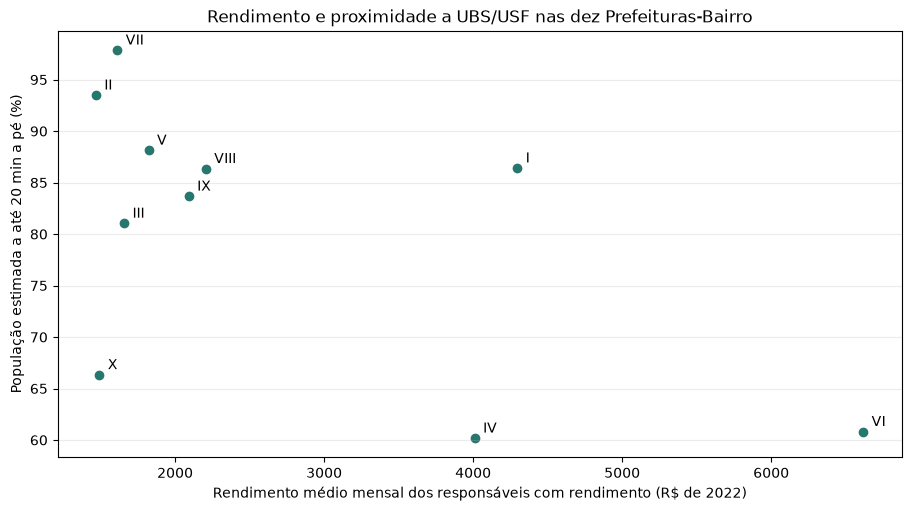

In [6]:
import matplotlib.pyplot as plt

cobertura_pb = pd.read_csv(
    "../resultados/tabelas/acesso_ubs_usf_por_prefeitura_bairro.csv",
    sep=";",
    decimal=",",
    encoding="utf-8-sig",
    dtype={"COD_PBR": "string"},
)

comparacao = renda_por_pb.merge(
    cobertura_pb[["COD_PBR", "pct_ate_20"]],
    on="COD_PBR",
    how="inner",
    validate="one_to_one",
)

assert len(comparacao) == 10, "Confira se as dez regiões entraram no cruzamento."
assert comparacao[["renda_media_rs", "pct_ate_20"]].notna().all().all()

# Spearman é a correlação entre as posições no ranking das duas variáveis.
rho = comparacao["renda_media_rs"].rank().corr(
    comparacao["pct_ate_20"].rank()
)
print(f"Spearman: {rho:.3f}")

fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
ax.scatter(comparacao["renda_media_rs"], comparacao["pct_ate_20"], color="#26776e")

for linha in comparacao.itertuples():
    ax.annotate(
        linha.COD_PBR,
        (linha.renda_media_rs, linha.pct_ate_20),
        xytext=(6, 4),
        textcoords="offset points",
    )

ax.set_xlabel("Rendimento médio mensal dos responsáveis com rendimento (R$ de 2022)")
ax.set_ylabel("População estimada a até 20 min a pé (%)")
ax.set_title("Rendimento e proximidade a UBS/USF nas dez Prefeituras-Bairro")
ax.grid(axis="y", alpha=0.25)
plt.show()

In [7]:
saida = Path("../resultados/graficos/renda_e_cobertura_ubs_usf.png")
saida.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(saida, dpi=200, bbox_inches="tight", facecolor="white")

In [9]:

prefeituras = gpd.read_file(
    "../dados/brutos/bairros/prefeitura_bairro.gpkg",
    layer="prefeituras_bairro_a",
).to_crs(epsg=31984)

unidades = gpd.read_file(
    "../dados/brutos/saude/saude.gpkg",
    layer="sau_p",
).to_crs(prefeituras.crs)

unidades["tipo_tratado"] = unidades["tipo_1"].astype("string").str.strip().str.upper()
unidades = unidades.loc[unidades["tipo_tratado"].isin(["UBS", "USF"])].copy()
unidades = unidades.reset_index(drop=True)

unidades_por_pb = gpd.sjoin(
    unidades[["unidade", "tipo_tratado", "geometry"]],
    prefeituras[["COD_PBR", "geometry"]],
    how="left",
    predicate="intersects",
)

# Se um ponto cair em duas regiões, revise antes de contá-lo duas vezes.
assert unidades_por_pb.index.is_unique, "Há unidades associadas a mais de uma região."
print("Unidades fora do recorte:", unidades_por_pb["COD_PBR"].isna().sum())

contagem = (
    unidades_por_pb.dropna(subset=["COD_PBR"])
    .groupby(["COD_PBR", "tipo_tratado"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["UBS", "USF"], fill_value=0)
    .reset_index()
)

renda_e_unidades = renda_por_pb[
    ["COD_PBR", "PREF_BAIRR", "renda_media_rs"]
].merge(contagem, on="COD_PBR", how="left", validate="one_to_one")

renda_e_unidades[["UBS", "USF"]] = (
    renda_e_unidades[["UBS", "USF"]].fillna(0).astype(int)
)
renda_e_unidades["total_ubs_usf"] = renda_e_unidades["UBS"] + renda_e_unidades["USF"]

renda_e_unidades = (
    renda_e_unidades
    .merge(
        prefeituras[["COD_PBR", "QTD_BAIRRO"]]
        .rename(columns={"QTD_BAIRRO": "qtd_bairros"}),
        on="COD_PBR",
        how="left",
        validate="one_to_one",
    )
    .merge(
        renda_por_pb[["COD_PBR", "pop_total"]]
        .rename(columns={"pop_total": "pop_estimada"}),
        on="COD_PBR",
        how="left",
        validate="one_to_one",
    )
)

colunas = [
    "COD_PBR", "PREF_BAIRR", "qtd_bairros", "pop_estimada",
    "renda_media_rs", "UBS", "USF", "total_ubs_usf",
]

tabela_final = renda_e_unidades[colunas].copy()

print(
    tabela_final.sort_values("renda_media_rs")
    .round({"pop_estimada": 0, "renda_media_rs": 2})
    .to_string(index=False)
)

Unidades fora do recorte: 0
COD_PBR                                       PREF_BAIRR  qtd_bairros  pop_estimada  renda_media_rs  UBS  USF  total_ubs_usf
     II          Prefeitura-bairro II - Subúrbio / Ilhas           19      258469.0         1469.18    3   24             27
      X                    Prefeitura-bairro X - Valéria            4       76518.0         1492.67    1    5              6
    VII  Prefeitura-bairro VII - Liberdade / São Caetano           19      297580.0         1613.02    5    9             14
    III               Prefeitura-bairro III - Cajazeiras           17      191965.0         1658.59    3   10             13
      V               Prefeitura-bairro V - Cidade Baixa           14      146910.0         1823.03    2    5              7
     IX              Prefeitura-bairro IX -  Pau da Lima           13      173316.0         2092.28    5    8             13
   VIII Prefeitura-bairro VIII - Cabula / Tancredo Neves           22      317896.0         2206.

In [10]:
tabela_final["ubs_usf_por_10_mil"] = (
    10_000 * tabela_final["total_ubs_usf"] / tabela_final["pop_estimada"]
)

display(
    tabela_final[
        ["PREF_BAIRR", "pop_estimada", "total_ubs_usf", "ubs_usf_por_10_mil"]
    ]
    .sort_values("ubs_usf_por_10_mil")
    .round({"pop_estimada": 0, "ubs_usf_por_10_mil": 2})
)

,PREF_BAIRR,pop_estimada,total_ubs_usf,ubs_usf_por_10_mil
6,Prefeitura-bairro VI - Barra / Pituba,322348.0,9,0.28
7,Prefeitura-bairro VII - Liberdade / São Caetano,297580.0,14,0.47
5,Prefeitura-bairro V - Cidade Baixa,146910.0,7,0.48
3,Prefeitura-bairro IV - Itapuã / Ipitanga,386586.0,19,0.49
8,Prefeitura-bairro VIII - Cabula / Tancredo Neves,317896.0,19,0.60
0,Prefeitura-bairro I - Centro / Brotas,238643.0,15,0.63
2,Prefeitura-bairro III - Cajazeiras,191965.0,13,0.68
4,Prefeitura-bairro IX - Pau da Lima,173316.0,13,0.75
9,Prefeitura-bairro X - Valéria,76518.0,6,0.78
1,Prefeitura-bairro II - Subúrbio / Ilhas,258469.0,27,1.04


In [11]:

cobertura_pb = pd.read_csv(
    "../resultados/tabelas/acesso_ubs_usf_por_prefeitura_bairro.csv",
    sep=";",
    decimal=",",
    encoding="utf-8-sig",
    dtype={"COD_PBR": "string"},
)

tabela_consolidada = tabela_final.merge(
    cobertura_pb[["COD_PBR", "pct_ate_20"]],
    on="COD_PBR",
    how="left",
    validate="one_to_one",
).sort_values("pct_ate_20").reset_index(drop=True)

assert len(tabela_consolidada) == 10, "A tabela deve ter dez regiões."
assert tabela_consolidada["pct_ate_20"].notna().all(), "Faltou cobertura em alguma região."
assert tabela_consolidada["total_ubs_usf"].sum() == 142, "Confira a contagem de unidades."

saida = Path("../resultados/tabelas/indicadores_por_prefeitura_bairro.csv")
saida.parent.mkdir(parents=True, exist_ok=True)
tabela_consolidada.to_csv(
    saida, index=False, sep=";", decimal=",", encoding="utf-8-sig"
)

display(tabela_consolidada.round({
    "pop_estimada": 0,
    "renda_media_rs": 2,
    "ubs_usf_por_10_mil": 2,
    "pct_ate_20": 2,
}))
print("Arquivo salvo em:", saida.resolve())

,COD_PBR,PREF_BAIRR,qtd_bairros,pop_estimada,renda_media_rs,UBS,USF,total_ubs_usf,ubs_usf_por_10_mil,pct_ate_20
0,IV,Prefeitura-bairro IV - Itapuã / Ipitanga,17,386586.0,4010.82,5,14,19,0.49,60.18
1,VI,Prefeitura-bairro VI - Barra / Pituba,23,322348.0,6617.8,3,6,9,0.28,60.82
2,X,Prefeitura-bairro X - Valéria,4,76518.0,1492.67,1,5,6,0.78,66.34
3,III,Prefeitura-bairro III - Cajazeiras,17,191965.0,1658.59,3,10,13,0.68,81.05
4,IX,Prefeitura-bairro IX - Pau da Lima,13,173316.0,2092.28,5,8,13,0.75,83.68
5,VIII,Prefeitura-bairro VIII - Cabula / Tancredo Neves,22,317896.0,2206.47,10,9,19,0.60,86.36
6,I,Prefeitura-bairro I - Centro / Brotas,23,238643.0,4296.85,8,7,15,0.63,86.42
7,V,Prefeitura-bairro V - Cidade Baixa,14,146910.0,1823.03,2,5,7,0.48,88.15
8,II,Prefeitura-bairro II - Subúrbio / Ilhas,19,258469.0,1469.18,3,24,27,1.04,93.50
9,VII,Prefeitura-bairro VII - Liberdade / São Caetano,19,297580.0,1613.02,5,9,14,0.47,97.87


Arquivo salvo em: /home/emanu/projetos/ftl-projeto-final/resultados/tabelas/indicadores_por_prefeitura_bairro.csv
